In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
day10_input_path = Path(
    "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"
)

if not day10_input_path.exists():
    raise FileNotFoundError(
        f"Input dataset not found: {day10_input_path.resolve()}"
    )

df_day10_source = pd.read_csv(
    day10_input_path,
    encoding="cp1252",
    low_memory=False
)

df_day10 = df_day10_source.copy()

print("Day 10 source dataset loaded successfully.")
print("Dataset shape:", df_day10.shape)

display(df_day10.head())

Day 10 source dataset loaded successfully.
Dataset shape: (180519, 56)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode,Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Revenue_Per_Unit,Profit_Margin,Discount_Level,Region_Market,Shipping_Mode_Rank,Is_Corporate_Customer,Order_Quantity_Category,Operational_Risk_Profile,Delivery_Status,Risk_Status
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,78521.0,3,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class,2,1,0,0,Major Delay,0.666667,99.99,0.319412,Low Discount,Pacific Asia - South Asia,4,0,Large,High Risk - Slower Shipping,Delayed,High Risk
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class,0,0,1,0,On Time / Early,1.000000,39.99,0.243611,Medium Discount,LATAM - Central America,4,0,Large,Lower Risk,On Time,Low Risk
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class,0,0,1,0,On Time / Early,1.000000,199.99,0.436822,Low Discount,LATAM - Central America,4,0,Small,Lower Risk,On Time,Low Risk
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class,2,1,0,0,Major Delay,0.666667,199.99,-0.209460,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class,2,1,0,0,Major Delay,0.666667,50.00,0.200000,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk


## Dataset Overview & Validation

In [3]:
print("Total rows:", len(df_day10))
print("Total columns:", len(df_day10.columns))
print("Duplicate rows:", df_day10.duplicated().sum())

required_columns = [
    "Order Country",
    "Market",
    "Is_Delayed",
    "Late_delivery_risk",
    "Shipping_Delay_Days",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Delay_Severity",
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Delivery_Efficiency_Ratio"
]

missing_columns = [
    col for col in required_columns
    if col not in df_day10.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are available.")

Total rows: 180519
Total columns: 56
Duplicate rows: 0
All required columns are available.


In [4]:
country_analysis_columns = [
    "Order Country",
    "Market",
    "Is_Delayed",
    "Late_delivery_risk",
    "Shipping_Delay_Days",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Delay_Severity",
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Delivery_Efficiency_Ratio"
]

country_missing_summary = (
    df_day10[country_analysis_columns]
    .isna()
    .sum()
    .to_frame(name="Missing_Values")
)

display(country_missing_summary)

,Missing_Values
Order Country,0
Market,0
Is_Delayed,0
Late_delivery_risk,0
Shipping_Delay_Days,0
Days for shipping (real),0
Days for shipment (scheduled),0
Delivery Status,0
Delay_Severity,0
Sales,0


## Inspect Country Count

In [5]:
print(
    "Missing country records:",
    df_day10["Order Country"].isna().sum()
)

print(
    "Unique country labels:",
    df_day10["Order Country"].nunique(dropna=True)
)

country_labels = (
    df_day10["Order Country"]
    .value_counts(dropna=False)
    .rename_axis("Order Country")
    .reset_index(name="Shipment_Count")
)

display(country_labels.head(20))

Missing country records: 0
Unique country labels: 164


,Order Country,Shipment_Count
0,Estados Unidos,24840
1,Francia,13222
2,México,13172
3,Alemania,9564
4,Australia,8497
5,Brasil,7987
6,Reino Unido,7302
7,China,5758
8,Italia,4989
9,India,4783


In [6]:
country_text = df_day10["Order Country"].dropna().astype(str)

whitespace_country_labels = sorted(
    country_text[
        country_text.ne(country_text.str.strip())
    ].unique()
)

print("Country labels with leading/trailing whitespace:")
print(whitespace_country_labels)

Country labels with leading/trailing whitespace:
[]


## Country Shipment Analysis

In [7]:
country_shipment_summary = (
    df_day10.dropna(subset=["Order Country"])
    .groupby("Order Country")
    .size()
    .reset_index(name="Total_Shipments")
    .sort_values(
        "Total_Shipments",
        ascending=False
    )
    .reset_index(drop=True)
)

total_valid_country_shipments = (
    country_shipment_summary["Total_Shipments"].sum()
)

country_shipment_summary["Shipment_Share_%"] = (
    country_shipment_summary["Total_Shipments"]
    / total_valid_country_shipments
    * 100
)

display(country_shipment_summary.head(15))

,Order Country,Total_Shipments,Shipment_Share_%
0,Estados Unidos,24840,13.760324
1,Francia,13222,7.324437
2,México,13172,7.296739
3,Alemania,9564,5.298057
4,Australia,8497,4.706984
5,Brasil,7987,4.424465
6,Reino Unido,7302,4.045004
7,China,5758,3.189692
8,Italia,4989,2.763698
9,India,4783,2.649583


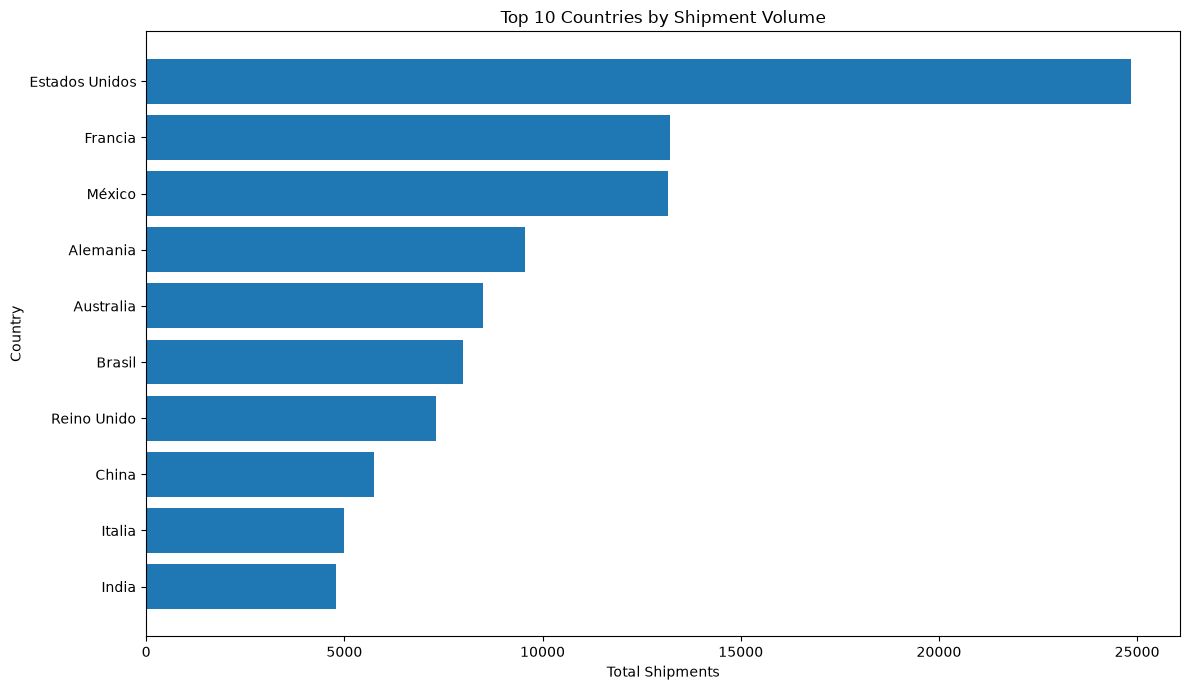

In [8]:
top_10_countries_by_shipments = (
    country_shipment_summary
    .head(10)
    .sort_values("Total_Shipments")
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_countries_by_shipments["Order Country"],
    top_10_countries_by_shipments["Total_Shipments"]
)

plt.title("Top 10 Countries by Shipment Volume")
plt.xlabel("Total Shipments")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## Country Delay Analysis

In [9]:
country_delay_analysis = (
    df_day10.dropna(subset=["Order Country"])
    .groupby("Order Country")
    .agg(
        Total_Shipments=("Is_Delayed", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Delay_Days=("Shipping_Delay_Days", "mean"),
        Average_Actual_Shipping_Days=(
            "Days for shipping (real)", "mean"
        ),
        Average_Scheduled_Shipping_Days=(
            "Days for shipment (scheduled)", "mean"
        ),
        Risk_Flagged_Shipments=(
            "Late_delivery_risk", "sum"
        )
    )
    .reset_index()
)

country_delay_analysis["On_Time_Shipments"] = (
    country_delay_analysis["Total_Shipments"]
    - country_delay_analysis["Delayed_Shipments"]
)

country_delay_analysis["Actual_Delay_Rate_%"] = (
    country_delay_analysis["Delayed_Shipments"]
    / country_delay_analysis["Total_Shipments"]
    * 100
)

country_delay_analysis["On_Time_Rate_%"] = (
    country_delay_analysis["On_Time_Shipments"]
    / country_delay_analysis["Total_Shipments"]
    * 100
)

country_delay_analysis["Risk_Flag_Rate_%"] = (
    country_delay_analysis["Risk_Flagged_Shipments"]
    / country_delay_analysis["Total_Shipments"]
    * 100
)

country_delay_analysis = (
    country_delay_analysis
    .sort_values(
        ["Actual_Delay_Rate_%", "Total_Shipments"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(country_delay_analysis.head(15))

,Order Country,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Risk_Flagged_Shipments,On_Time_Shipments,Actual_Delay_Rate_%,On_Time_Rate_%,Risk_Flag_Rate_%
0,Luxemburgo,10,10,2.700000,5.500000,2.800000,10,0,100.000000,0.000000,100.000000
1,Laos,6,6,1.833333,5.833333,4.000000,6,0,100.000000,0.000000,100.000000
2,Armenia,5,5,1.000000,2.000000,1.000000,5,0,100.000000,0.000000,100.000000
3,Bután,5,5,2.000000,6.000000,4.000000,5,0,100.000000,0.000000,100.000000
4,República de Gambia,5,5,2.000000,4.000000,2.000000,5,0,100.000000,0.000000,100.000000
5,Suazilandia,5,5,2.000000,6.000000,4.000000,5,0,100.000000,0.000000,100.000000
6,Sudán del Sur,5,5,2.200000,3.800000,1.600000,5,0,100.000000,0.000000,100.000000
7,Eritrea,2,2,2.000000,6.000000,4.000000,2,0,100.000000,0.000000,100.000000
8,Guinea Ecuatorial,2,2,1.500000,3.500000,2.000000,2,0,100.000000,0.000000,100.000000
9,Sáhara Occidental,2,2,2.000000,6.000000,4.000000,2,0,100.000000,0.000000,100.000000


In [10]:
country_delayed_duration = (
    df_day10[
        df_day10["Is_Delayed"].eq(1)
        & df_day10["Order Country"].notna()
    ]
    .groupby("Order Country")
    .agg(
        Delayed_Shipments=("Is_Delayed", "size"),
        Average_Delay_Among_Delayed=(
            "Shipping_Delay_Days", "mean"
        ),
        Maximum_Delay_Among_Delayed=(
            "Shipping_Delay_Days", "max"
        )
    )
    .reset_index()
    .sort_values(
        "Average_Delay_Among_Delayed",
        ascending=False
    )
)

display(country_delayed_duration.head(15))

,Order Country,Delayed_Shipments,Average_Delay_Among_Delayed,Maximum_Delay_Among_Delayed
86,Macedonia,1,3.000000,3
84,Luxemburgo,10,2.700000,4
92,Mauritania,8,2.625000,3
93,Moldavia,56,2.375000,4
87,Madagascar,74,2.297297,4
32,Costa Rica,25,2.280000,4
128,Siria,36,2.250000,4
43,Eslovenia,5,2.200000,3
134,Sudán del Sur,5,2.200000,3
94,Mongolia,52,2.134615,4


## Compare Country Delay Rates

In [11]:
minimum_shipments_for_comparison = 100

eligible_countries = country_delay_analysis[
    country_delay_analysis["Total_Shipments"]
    >= minimum_shipments_for_comparison
].copy()

if eligible_countries.empty:
    print(
        "No countries meet the minimum shipment threshold."
    )
else:
    highest_delay_countries = (
        eligible_countries
        .sort_values(
            ["Actual_Delay_Rate_%", "Total_Shipments"],
            ascending=[False, False]
        )
        .head(10)
    )

    lowest_delay_countries = (
        eligible_countries
        .sort_values(
            ["Actual_Delay_Rate_%", "Total_Shipments"],
            ascending=[True, False]
        )
        .head(10)
    )

    print("Top 10 countries by actual delay rate:")
    display(highest_delay_countries)

    print("Bottom 10 countries by actual delay rate:")
    display(lowest_delay_countries)

Top 10 countries by actual delay rate:


,Order Country,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Risk_Flagged_Shipments,On_Time_Shipments,Actual_Delay_Rate_%,On_Time_Rate_%,Risk_Flag_Rate_%
24,Ecuador,294,204,0.642857,3.340136,2.697279,197,90,69.387755,30.612245,67.006803
29,Níger,108,72,0.787037,3.972222,3.185185,69,36,66.666667,33.333333,63.888889
31,Mozambique,244,162,0.864754,3.729508,2.864754,156,82,66.393443,33.606557,63.934426
35,Irlanda,491,318,0.743381,3.490835,2.747454,298,173,64.765784,35.234216,60.692464
36,Trinidad y Tobago,138,89,0.942029,4.137681,3.195652,81,49,64.492754,35.507246,58.695652
37,Hungría,179,115,0.625698,3.843575,3.217877,112,64,64.245810,35.754190,62.569832
38,Somalia,141,90,0.546099,2.978723,2.432624,90,51,63.829787,36.170213,63.829787
39,Ghana,264,168,0.939394,3.859848,2.920455,160,96,63.636364,36.363636,60.606061
40,Angola,306,192,0.879085,3.401961,2.522876,183,114,62.745098,37.254902,59.803922
41,Malasia,544,341,0.623162,3.334559,2.711397,333,203,62.683824,37.316176,61.213235


Bottom 10 countries by actual delay rate:


,Order Country,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Risk_Flagged_Shipments,On_Time_Shipments,Actual_Delay_Rate_%,On_Time_Rate_%,Risk_Flag_Rate_%
149,Togo,122,47,0.147541,3.286885,3.139344,45,75,38.524590,61.475410,36.885246
139,Dinamarca,285,131,0.256140,3.750877,3.494737,128,154,45.964912,54.035088,44.912281
138,Libia,105,49,0.057143,3.114286,3.057143,49,56,46.666667,53.333333,46.666667
137,Camerún,275,129,0.254545,3.185455,2.930909,121,146,46.909091,53.090909,44.000000
135,Senegal,263,126,0.209125,3.467681,3.258555,116,137,47.908745,52.091255,44.106464
134,Finlandia,290,139,0.403448,3.589655,3.186207,139,151,47.931034,52.068966,47.931034
132,Madagascar,149,74,0.738255,3.771812,3.033557,74,75,49.664430,50.335570,49.664430
130,Sudán,251,128,0.482072,3.450199,2.968127,126,123,50.996016,49.003984,50.199203
129,Bielorrusia,210,108,0.523810,3.595238,3.071429,107,102,51.428571,48.571429,50.952381
128,Panamá,1941,1004,0.360124,3.414735,3.054611,984,937,51.725914,48.274086,50.695518


### High delay rates

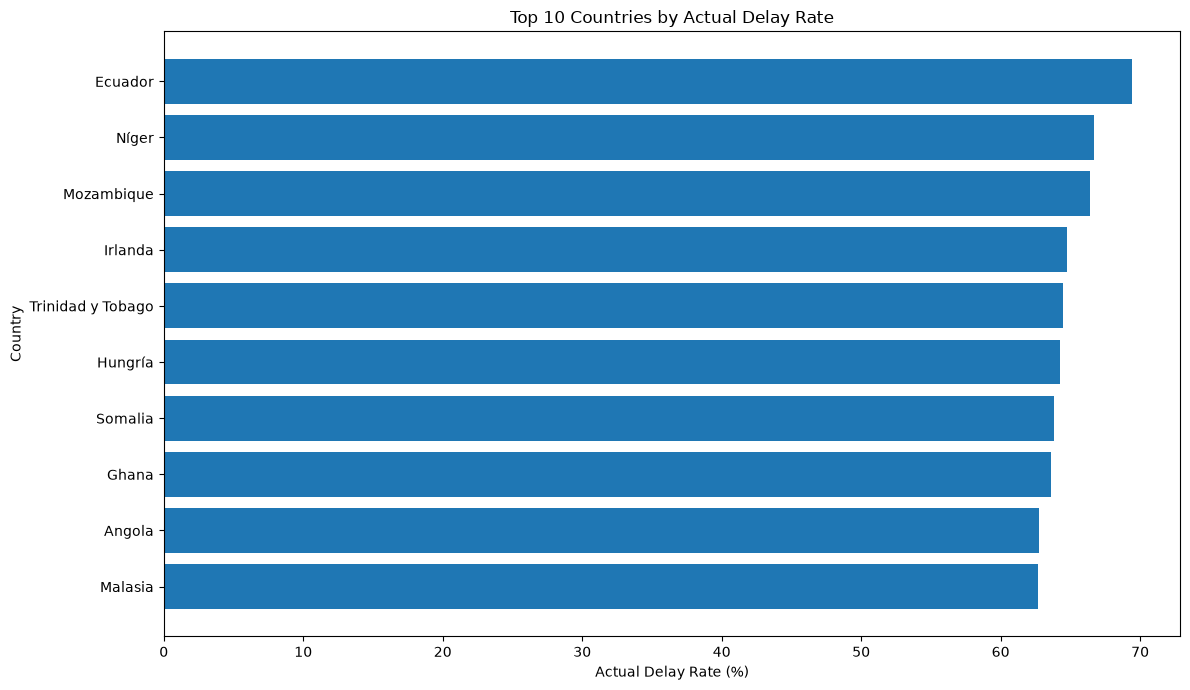

In [12]:
top_10_delay_rate = (
    highest_delay_countries
    .sort_values("Actual_Delay_Rate_%")
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_delay_rate["Order Country"],
    top_10_delay_rate["Actual_Delay_Rate_%"]
)

plt.title("Top 10 Countries by Actual Delay Rate")
plt.xlabel("Actual Delay Rate (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Low delay rates

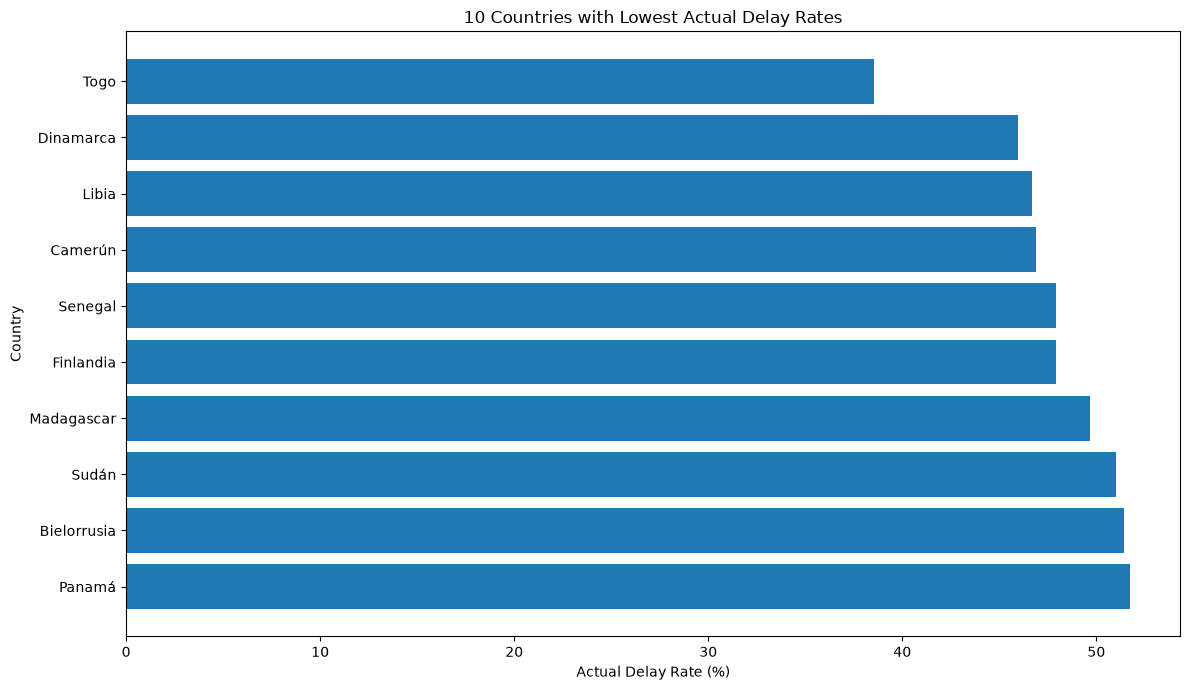

In [13]:
bottom_10_delay_rate = (
    lowest_delay_countries
    .sort_values("Actual_Delay_Rate_%", ascending=False)
)

plt.figure(figsize=(12, 7))

plt.barh(
    bottom_10_delay_rate["Order Country"],
    bottom_10_delay_rate["Actual_Delay_Rate_%"]
)

plt.title("10 Countries with Lowest Actual Delay Rates")
plt.xlabel("Actual Delay Rate (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## Country Delay Severity Analysis

In [14]:
country_delay_severity_counts = (
    df_day10.dropna(subset=["Order Country"])
    .groupby(
        ["Order Country", "Delay_Severity"],
        observed=True
    )
    .size()
    .reset_index(name="Shipment_Count")
)

country_severity_totals = (
    country_delay_severity_counts
    .groupby("Order Country")["Shipment_Count"]
    .transform("sum")
)

country_delay_severity_counts["Severity_Share_%"] = (
    country_delay_severity_counts["Shipment_Count"]
    / country_severity_totals
    * 100
)

country_delay_severity_analysis = (
    country_delay_severity_counts
    .sort_values(
        ["Order Country", "Severity_Share_%"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(country_delay_severity_analysis.head(20))

,Order Country,Delay_Severity,Shipment_Count,Severity_Share_%
0,Afganistán,On Time / Early,65,39.877301
1,Afganistán,Minor Delay,60,36.809816
2,Afganistán,Major Delay,38,23.312883
3,Albania,Minor Delay,21,56.756757
4,Albania,On Time / Early,15,40.540541
5,Albania,Major Delay,1,2.702703
6,Alemania,On Time / Early,3923,41.018402
7,Alemania,Minor Delay,3375,35.288582
8,Alemania,Major Delay,2266,23.693015
9,Angola,On Time / Early,114,37.254902


### Create a country-level severity analysis 

In [15]:
country_delay_severity_pct = (
    country_delay_severity_counts
    .pivot(
        index="Order Country",
        columns="Delay_Severity",
        values="Severity_Share_%"
    )
    .fillna(0)
    .reset_index()
)

display(country_delay_severity_pct.head(15))

Delay_Severity,Order Country,Major Delay,Minor Delay,On Time / Early
0,Afganistán,23.312883,36.809816,39.877301
1,Albania,2.702703,56.756757,40.540541
2,Alemania,23.693015,35.288582,41.018402
3,Angola,25.816993,36.928105,37.254902
4,Arabia Saudí,19.302326,40.697674,40.000000
5,Argelia,28.875969,26.550388,44.573643
6,Argentina,22.837908,32.107716,45.054376
7,Armenia,0.000000,100.000000,0.000000
8,Australia,23.514181,32.893963,43.591856
9,Austria,21.701514,37.851478,40.447008


## Country Delivery Performance Analysis

In [16]:
country_performance = (
    df_day10.dropna(subset=["Order Country"])
    .groupby("Order Country")
    .agg(
        Total_Shipments=("Order Country", "size"),
        Total_Sales=("Sales", "sum"),
        Average_Sales_Per_Record=("Sales", "mean"),
        Total_Order_Profit=("Order Profit Per Order", "sum"),
        Average_Order_Profit=("Order Profit Per Order", "mean"),
        Total_Order_Item_Value=("Order Item Total", "sum"),
        Average_Actual_Shipping_Days=(
            "Days for shipping (real)", "mean"
        ),
        Average_Scheduled_Shipping_Days=(
            "Days for shipment (scheduled)", "mean"
        ),
        Valid_Efficiency_Observations=(
            "Delivery_Efficiency_Ratio", "count"
        ),
        Average_Delivery_Efficiency=(
            "Delivery_Efficiency_Ratio", "mean"
        )
    )
    .reset_index()
)

country_performance = country_performance.sort_values(
    "Total_Sales",
    ascending=False
).reset_index(drop=True)

display(country_performance.head(15))

,Order Country,Total_Shipments,Total_Sales,Average_Sales_Per_Record,Total_Order_Profit,Average_Order_Profit,Total_Order_Item_Value,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Valid_Efficiency_Observations,Average_Delivery_Efficiency
0,Estados Unidos,24840,4879667.57,196.443944,540413.07,21.755760,4385242.45,3.490620,2.914895,24075,0.904883
1,Francia,13222,2879942.31,217.814424,327828.58,24.794175,2590323.47,3.486084,2.889654,12830,0.901554
2,México,13172,2633195.24,199.908536,303278.37,23.024474,2368426.06,3.536441,2.943137,12842,0.911483
3,Alemania,9564,2074171.78,216.872834,194827.08,20.370878,1862577.57,3.519239,2.925972,9318,0.901381
4,Australia,8497,1694621.64,199.437642,170041.58,20.011955,1521410.40,3.497705,2.927504,8163,0.903169
5,Reino Unido,7302,1612094.82,220.774421,180942.88,24.779907,1450047.22,3.478773,2.950835,7086,0.927594
6,Brasil,7987,1594319.92,199.614363,186713.64,23.377193,1433100.98,3.540253,2.973332,7788,0.917488
7,China,5758,1172902.09,203.699564,122190.92,21.221070,1052752.57,3.517888,2.957451,5593,0.914220
8,Italia,4989,1072181.65,214.909130,121545.47,24.362692,963830.33,3.453999,2.970335,4894,0.921959
9,India,4783,962396.68,201.211934,99746.82,20.854447,865968.88,3.518503,2.902990,4685,0.899851


## Create the Country Risk Table

In [17]:
country_risk_table = country_delay_analysis.merge(
    country_performance[
        [
            "Order Country",
            "Total_Sales",
            "Average_Order_Profit",
            "Valid_Efficiency_Observations",
            "Average_Delivery_Efficiency"
        ]
    ],
    on="Order Country",
    how="left",
    validate="one_to_one"
)

country_risk_table = country_risk_table.merge(
    country_delayed_duration[
        [
            "Order Country",
            "Average_Delay_Among_Delayed",
            "Maximum_Delay_Among_Delayed"
        ]
    ],
    on="Order Country",
    how="left",
    validate="one_to_one"
)

country_risk_table = country_risk_table.merge(
    country_delay_severity_pct,
    on="Order Country",
    how="left",
    validate="one_to_one"
)

country_risk_table = country_risk_table.sort_values(
    ["Actual_Delay_Rate_%", "Total_Shipments"],
    ascending=[False, False]
).reset_index(drop=True)

display(country_risk_table.head(20))

,Order Country,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Risk_Flagged_Shipments,On_Time_Shipments,Actual_Delay_Rate_%,On_Time_Rate_%,Risk_Flag_Rate_%,Total_Sales,Average_Order_Profit,Valid_Efficiency_Observations,Average_Delivery_Efficiency,Average_Delay_Among_Delayed,Maximum_Delay_Among_Delayed,Major Delay,Minor Delay,On Time / Early
0,Luxemburgo,10,10,2.700000,5.500000,2.800000,10,0,100.000000,0.000000,100.000000,1764.72,48.313000,10,0.520000,2.700000,4.0,70.000000,30.000000,0.000000
1,Laos,6,6,1.833333,5.833333,4.000000,6,0,100.000000,0.000000,100.000000,683.01,14.015000,6,0.688889,1.833333,2.0,83.333333,16.666667,0.000000
2,Armenia,5,5,1.000000,2.000000,1.000000,5,0,100.000000,0.000000,100.000000,455.90,8.492000,5,0.500000,1.000000,1.0,0.000000,100.000000,0.000000
3,Bután,5,5,2.000000,6.000000,4.000000,5,0,100.000000,0.000000,100.000000,769.60,41.734000,5,0.666667,2.000000,2.0,100.000000,0.000000,0.000000
4,República de Gambia,5,5,2.000000,4.000000,2.000000,5,0,100.000000,0.000000,100.000000,1449.86,-53.166000,5,0.500000,2.000000,2.0,100.000000,0.000000,0.000000
5,Suazilandia,5,5,2.000000,6.000000,4.000000,5,0,100.000000,0.000000,100.000000,1259.91,62.492000,5,0.666667,2.000000,2.0,100.000000,0.000000,0.000000
6,Sudán del Sur,5,5,2.200000,3.800000,1.600000,5,0,100.000000,0.000000,100.000000,879.94,44.556000,5,0.440000,2.200000,3.0,60.000000,40.000000,0.000000
7,Eritrea,2,2,2.000000,6.000000,4.000000,2,0,100.000000,0.000000,100.000000,309.96,46.240000,2,0.666667,2.000000,2.0,100.000000,0.000000,0.000000
8,Guinea Ecuatorial,2,2,1.500000,3.500000,2.000000,2,0,100.000000,0.000000,100.000000,319.96,51.680000,2,0.583333,1.500000,2.0,50.000000,50.000000,0.000000
9,Sáhara Occidental,2,2,2.000000,6.000000,4.000000,2,0,100.000000,0.000000,100.000000,599.96,-8.760000,2,0.666667,2.000000,2.0,100.000000,0.000000,0.000000


## Create a Country KPI Summary

In [18]:
if country_delay_analysis.empty:
    raise ValueError(
        "Country delay analysis is empty. "
        "Check the source dataset and country labels."
    )

eligible_kpis = country_delay_analysis[
    country_delay_analysis["Total_Shipments"]
    >= minimum_shipments_for_comparison
].copy()

highest_volume_row = (
    country_shipment_summary
    .sort_values("Total_Shipments", ascending=False)
    .iloc[0]
)

kpi_records = [
    {
        "Metric": "Total Shipment Records",
        "Value": len(df_day10)
    },
    {
        "Metric": "Unique Country Labels",
        "Value": df_day10["Order Country"].nunique()
    },
    {
        "Metric": "Records with Missing Country",
        "Value": df_day10["Order Country"].isna().sum()
    },
    {
        "Metric": "Countries with at Least 100 Shipments",
        "Value": len(eligible_kpis)
    },
    {
        "Metric": "Country with Highest Shipment Volume",
        "Value": highest_volume_row["Order Country"]
    },
    {
        "Metric": "Highest Country Shipment Count",
        "Value": highest_volume_row["Total_Shipments"]
    }
]

if not eligible_kpis.empty:

    highest_delay_row = (
        eligible_kpis
        .sort_values(
            ["Actual_Delay_Rate_%", "Total_Shipments"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    lowest_delay_row = (
        eligible_kpis
        .sort_values(
            ["Actual_Delay_Rate_%", "Total_Shipments"],
            ascending=[True, False]
        )
        .iloc[0]
    )

    kpi_records.extend([
        {
            "Metric": "Country with Highest Actual Delay Rate",
            "Value": highest_delay_row["Order Country"]
        },
        {
            "Metric": "Highest Actual Delay Rate (%)",
            "Value": round(
                highest_delay_row["Actual_Delay_Rate_%"], 2
            )
        },
        {
            "Metric": "Country with Lowest Actual Delay Rate",
            "Value": lowest_delay_row["Order Country"]
        },
        {
            "Metric": "Lowest Actual Delay Rate (%)",
            "Value": round(
                lowest_delay_row["Actual_Delay_Rate_%"], 2
            )
        }
    ])

day10_kpis = pd.DataFrame(kpi_records)

display(day10_kpis)

,Metric,Value
0,Total Shipment Records,180519
1,Unique Country Labels,164
2,Records with Missing Country,0
3,Countries with at Least 100 Shipments,96
4,Country with Highest Shipment Volume,Estados Unidos
5,Highest Country Shipment Count,24840
6,Country with Highest Actual Delay Rate,Ecuador
7,Highest Actual Delay Rate (%),69.39
8,Country with Lowest Actual Delay Rate,Togo
9,Lowest Actual Delay Rate (%),38.52


## Validate Country-Level Results

### Check 1 — Shipment totals reconcile

In [19]:
total_source_country_records = (
    df_day10["Order Country"].notna().sum()
)

total_country_summary_records = (
    country_shipment_summary["Total_Shipments"].sum()
)

shipment_totals_valid = (
    total_source_country_records
    == total_country_summary_records
)

print(
    "Country shipment totals reconcile:",
    shipment_totals_valid
)

print(
    "Source records with country labels:",
    total_source_country_records
)

print(
    "Summed country shipment records:",
    total_country_summary_records
)

Country shipment totals reconcile: True
Source records with country labels: 180519
Summed country shipment records: 180519


### Delayed shipments totals reconcile

In [21]:
valid_country_records = df_day10[
    df_day10["Order Country"].notna()
]

expected_delayed_records = valid_country_records[
    valid_country_records["Is_Delayed"].eq(1)
].shape[0]

calculated_delayed_records = (
    country_delay_analysis["Delayed_Shipments"].sum()
)

delayed_totals_valid = (
    expected_delayed_records
    == calculated_delayed_records
)

print(
    "Delayed shipment totals reconcile:",
    delayed_totals_valid
)

Delayed shipment totals reconcile: True


### Validate the delay-rate calculation

In [22]:
expected_delay_rate = (
    country_delay_analysis["Delayed_Shipments"]
    / country_delay_analysis["Total_Shipments"]
    * 100
)

delay_rates_valid = np.allclose(
    country_delay_analysis["Actual_Delay_Rate_%"],
    expected_delay_rate,
    equal_nan=True
)

print(
    "Country delay rates are correctly calculated:",
    delay_rates_valid
)

Country delay rates are correctly calculated: True


### Validate risk-table coverage

In [23]:
source_countries = set(
    df_day10["Order Country"].dropna().unique()
)

risk_table_countries = set(
    country_risk_table["Order Country"].dropna().unique()
)

risk_table_coverage_valid = (
    source_countries == risk_table_countries
)

print(
    "Country risk table covers all observed country labels:",
    risk_table_coverage_valid
)

Country risk table covers all observed country labels: True


### Validate delay indicators

In [24]:
print(
    "Unique Is_Delayed values:",
    sorted(df_day10["Is_Delayed"].dropna().unique().tolist())
)

print(
    "Missing Is_Delayed values:",
    df_day10["Is_Delayed"].isna().sum()
)

print(
    "Unique Late_delivery_risk values:",
    sorted(
        df_day10["Late_delivery_risk"]
        .dropna()
        .unique()
        .tolist()
    )
)

print(
    "Missing Late_delivery_risk values:",
    df_day10["Late_delivery_risk"].isna().sum()
)

Unique Is_Delayed values: [0, 1]
Missing Is_Delayed values: 0
Unique Late_delivery_risk values: [0, 1]
Missing Late_delivery_risk values: 0


## Saving Day 10 Results

In [27]:
day10_output_dir = Path("../data/analysis_data/")

if not day10_output_dir.exists():
    raise FileNotFoundError(
        "Output directory does not exist: "
        f"{day10_output_dir.resolve()}"
    )

day10_outputs = {
    "APL_Day10_Country_Shipment_Summary.csv":
        country_shipment_summary,

    "APL_Day10_Country_Delay_Analysis.csv":
        country_delay_analysis,

    "APL_Day10_Country_Delay_Severity.csv":
        country_delay_severity_analysis,

    "APL_Day10_Country_Delay_Severity_Percentages.csv":
        country_delay_severity_pct,

    "APL_Day10_Country_Performance.csv":
        country_performance,

    "APL_Day10_Country_Risk_Table.csv":
        country_risk_table,

    "APL_Day10_Country_KPIs.csv":
        day10_kpis,

    "APL_Day10_Country_Delayed_Duration.csv":
        country_delayed_duration
}

for filename, output_df in day10_outputs.items():

    output_path = day10_output_dir / filename

    output_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved:", output_path.resolve())

print("\nAll Day 10 outputs saved successfully.")

Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day10_Country_Shipment_Summary.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day10_Country_Delay_Analysis.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day10_Country_Delay_Severity.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day10_Country_Delay_Severity_Percentages.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day10_Country_Performance.csv
Saved: D:\Data Analytics Project\D

## Final Validation Report

In [28]:
validation_results = {
    "Source Dataset Loaded": not df_day10.empty,

    "Required Columns Available":
        len(missing_columns) == 0,

    "Country Shipment Totals Reconcile":
        shipment_totals_valid,

    "Delayed Shipment Totals Reconcile":
        delayed_totals_valid,

    "Country Delay Rates Valid":
        delay_rates_valid,

    "Country Risk Table Coverage Valid":
        risk_table_coverage_valid,

    "Country Shipment Summary Not Empty":
        not country_shipment_summary.empty,

    "Country Delay Analysis Not Empty":
        not country_delay_analysis.empty,

    "Country Risk Table Not Empty":
        not country_risk_table.empty,

    "All Output Files Exist":
        all(
            (day10_output_dir / filename).exists()
            for filename in day10_outputs
        )
}

day10_validation_report = pd.DataFrame(
    [
        {
            "Validation_Check": check,
            "Status": "PASS" if passed else "FAIL"
        }
        for check, passed in validation_results.items()
    ]
)

display(day10_validation_report)

if all(validation_results.values()):
    print("ALL DAY 10 VALIDATION CHECKS PASSED.")
else:
    print("DAY 10 VALIDATION REQUIRES ATTENTION.")

    display(
        day10_validation_report[
            day10_validation_report["Status"] == "FAIL"
        ]
    )

,Validation_Check,Status
0,Source Dataset Loaded,PASS
1,Required Columns Available,PASS
2,Country Shipment Totals Reconcile,PASS
3,Delayed Shipment Totals Reconcile,PASS
4,Country Delay Rates Valid,PASS
5,Country Risk Table Coverage Valid,PASS
6,Country Shipment Summary Not Empty,PASS
7,Country Delay Analysis Not Empty,PASS
8,Country Risk Table Not Empty,PASS
9,All Output Files Exist,PASS


ALL DAY 10 VALIDATION CHECKS PASSED.


## 15. Country Analysis — Key Findings

### 1. Shipment Volume
Identify the country with the highest shipment volume and explain
its contribution to the overall shipment workload.

### 2. Delivery Delays
Identify the countries with the highest and lowest actual delay rates,
using the minimum shipment threshold defined in this notebook.

### 3. Delay Duration
Identify countries with the longest average delay duration among
delayed shipments.

### 4. Delay Severity
Discuss the countries with the highest shares of major delays.

### 5. Delivery Performance
Compare shipping duration and delivery-efficiency metrics across countries.

### 6. Operational Risk
Identify countries that combine substantial shipment volume with
poor delivery performance.

### 7. Business Recommendations
Recommend which countries deserve further operational investigation.
Avoid claiming that a country causes delays unless the analysis
provides evidence for that conclusion.